# A Transformer-Based Approach for Raw EEG Classification

### 1. Setup and Imports

Import necessary libraries and set up the environment.



In [1]:
%load_ext autoreload
%autoreload 2 
#%autoreload 2 fa in modo che, ogni volta che modifichi e salvi un file .py, Jupyter ricarichi automaticamente le modifiche nel notebook senza chiederti di riavviare il kernel!†

In [3]:
import numpy as np
from pathlib import Path
import re
import sys

src_path = Path('../src/eeg-bci-transformer-pipeline').resolve()
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))
from datapreprocessing import EEGpreprocessing, EEGDataset
from train import EarlyStopper, EEGTrainer
from models import ScaledDotProductAttention, MultiHeadAttention, FeedForward, TransformerLayer, ConvolutionModule, EEGConformer, EEGTransformerConv1D

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import mne
import os
from sklearn.model_selection import KFold,GroupKFold
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

### 2. Configuration and Hyperparameters

Define all model and training parameters

### 3. Data Loading and Preprocessing

Load the PhysioNet EEG Motor Movement/Imagery Dataset 

In [4]:
CURRENT_DIR = Path.cwd()

DATASET_PATH = (CURRENT_DIR.parent / "data" / "MotorMovement(03,07,011)") if CURRENT_DIR.name == "notebook" else (CURRENT_DIR / "data" / "MotorMovement(03,07,011)")

print(f"Percorso dataset utilizzato: {DATASET_PATH}")

edf_files = sorted(DATASET_PATH.glob("**/*.edf"))

file_records = []
for edf_path in edf_files:
    filename = edf_path.stem
    match = re.search(r'S(\d+)', filename, re.IGNORECASE)
    if match:
        subj_id = int(match.group(1))
        file_records.append({'path': edf_path, 'subject_id': subj_id})

file_subject_ids = np.array([r['subject_id'] for r in file_records])
unique_subjects = np.unique(file_subject_ids)

# Split riproducibile sui SOGGETTI (Test set isolato)
np.random.seed(42)
shuffled_subjects = unique_subjects.copy()
np.random.shuffle(shuffled_subjects)

test_subjects = set(shuffled_subjects[:11])
train_val_subjects = set(shuffled_subjects[11:])

train_val_records = [r for r in file_records if r['subject_id'] in train_val_subjects]
test_records = [r for r in file_records if r['subject_id'] in test_subjects]

print(f"File EDF for Train/Validation: {len(train_val_records)}")
print(f"File EDF for TEST: {len(test_records)}")

Percorso dataset utilizzato: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorMovement(03,07,011)
File EDF for Train/Validation: 294
File EDF for TEST: 33


Apply preprocessing  #momontaneamente lo faccio solo sul train/val perchè non sono sicura vada fatto sul test, riparlarne con luca

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import mne

X_raw_list = []
y_list = []
subject_ids_list = []
psd_records = []  # 📊 Lista per salvare i valori numerici della PSD

for i, rec in enumerate(train_val_records):
    file_path = rec['path']
    subj_id = rec['subject_id']

    raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)

    pipeline = EEGpreprocessing(raw)
    pipeline.bandpassfilter(l_freq=8.0, h_freq=30.0, target_sfreq=160.0)
    epochs_mne = pipeline.epoching(tmin=0.0, tmax=4.0)

    # 1. CALCOLO CORRETTO DELLA PSD (Metodo moderno di MNE)
    psd_object = epochs_mne.compute_psd(fmin=1, fmax=40, method='welch')
    
    # 2. ESTRAZIONE DEI VALORI NUMERICI DELLA PSD
    psd_values, freqs = psd_object.get_data(return_freqs=True) 
    # Shape di psd_values: (n_epochs, n_channels, n_freqs)
    
    # Salviamo i valori numerici associati al soggetto
    psd_records.append({
        'subject_id': subj_id,
        'frequencies': freqs,                # Vettore delle frequenze (es. 1 Hz, 2 Hz, ...)
        'psd_data': psd_values,              # Valori di potenza spettrale
        'mean_power_per_channel': np.mean(psd_values, axis=(0, 2)) # Potenza media per canale
    })


    if len(epochs_mne) == 0:
        continue
    
    # Estraiamo i dati grezzi delle epoche
    X_raw = epochs_mne.get_data(copy=True) 

    y = epochs_mne.events[:, -1]
    event_id = epochs_mne.event_id
    labels = np.zeros(len(y), dtype=np.int64)
    labels[y == event_id['Left']] = 0
    labels[y == event_id['Right']] = 1

    X_raw_list.append(X_raw)
    y_list.append(labels)
    subject_ids_list.extend([subj_id] * len(X_raw))

Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 project

/tmp/ipykernel_25370/785558903.py:14: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 12 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)


/tmp/ipykernel_25370/785558903.py:14: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)
/tmp/ipykernel_25370/785558903.py:14: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 12 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 project

In [19]:
'''
for i, record in enumerate(psd_records[:4]):
    print(f"--- Paziente {i+1} ---")
    print(f"Subject ID: {record['subject_id']}")
    print(f"Shape della PSD (epoche, canali, frequenze): {record['psd_data'].shape}")
    print(f"Potenza media per canale (primi 5 canali): {record['mean_power_per_channel'][:63]}")
    print("-" * 30)
'''

'\nfor i, record in enumerate(psd_records[:4]):\n    print(f"--- Paziente {i+1} ---")\n    print(f"Subject ID: {record[\'subject_id\']}")\n    print(f"Shape della PSD (epoche, canali, frequenze): {record[\'psd_data\'].shape}")\n    print(f"Potenza media per canale (primi 5 canali): {record[\'mean_power_per_channel\'][:63]}")\n    print("-" * 30)\n'

Convert to PyTorch tensors

In [7]:
X_training_validation_raw = np.concatenate(X_raw_list, axis=0)
y_training_validation = np.concatenate(y_list, axis=0)
subjects_ids_training_validation = np.array(subject_ids_list)

print(f"Dimensioni X_train_val grezzo: {X_training_validation_raw.shape}")
print(f"Dimensioni y_train_val: {y_training_validation.shape}")
print("Distribuzione etichette:", np.unique(y_training_validation, return_counts=True))

Dimensioni X_train_val grezzo: (4402, 64, 641)
Dimensioni y_train_val: (4402,)
Distribuzione etichette: (array([0, 1]), array([2203, 2199]))


In [8]:
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)


### Cross-Individual 3-Fold Cross-Validation and Random grid search to tuning hyperparameters

## Gfk 

In [ ]:

# ==========================================
# 3. CICLO DI CROSS-VALIDATION COMPLETO (5 FOLD - GROUP K-FOLD)
# ==========================================
EPOCHS = 30
all_fold_best_accs = []
all_fold_best_losses = []

print("==========================================")
print("🚀 INIZIO CROSS-VALIDATION 5-FOLD COMPLETA CON I PARAMETRI OTTIMALI")
print("==========================================")

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- INIZIO TRAINING & VALIDAZIONE - FOLD {fold + 1}/5 (Cross-Subject) ---")

    # A. Divisione dei dati grezzi in base al fold del GroupKFold
    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]

    # B. Calcolo Media e Std per-canale ESCLUSIVAMENTE sul Training Set (Prevenzione Data Leakage)
    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    # C. Normalizzazione + Data Augmentation (Rumore Gaussiano) solo sul Train
    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    # D. Normalizzazione pura sul Validation Set (usando media e std del Train)
    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    # E. Creazione Dataset e DataLoader PyTorch
    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

    # F. Inizializzazione del Modello EEG Conformer con i parametri vincenti della Grid Search
    model = EEGConformer(
        num_channels=64, time_steps=641, d_model=32, 
        nhead=4, num_layers=1, d_ff=128, 
        dropout=best_hyperparams['dropout'], num_classes=2
    ).to(device)
    
    # G. Ottimizzatore, Loss e Scheduler configurati con i iperparametri ottimali
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(), lr=best_hyperparams['lr'], weight_decay=best_hyperparams['weight_decay'])
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

    # H. Inizializzazione della classe EEGTrainer
    trainer = EEGTrainer(
        model=model, 
        criterion=criterion, 
        optimizer=optimizer,  
        device=device
    )
    trainer.scheduler = scheduler

    # I. Avvio dell'addestramento tramite il metodo della classe
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
        train_loader=train_loader, 
        val_loader=val_loader, 
        epochs=EPOCHS,
        scheduler=scheduler
    )

    max_fold_acc = max(val_accuracies)
    min_fold_loss = min(val_losses)
    
    all_fold_best_accs.append(max_fold_acc)
    all_fold_best_losses.append(min_fold_loss)

    print(f"✅ Fold {fold + 1} completato | Min Val Loss: {min_fold_loss:.4f} | Max Val Acc: {max_fold_acc*100:.2f}%")

    # ==========================================
    # L. PLOT DELLE CURVE DI LOSS E ACCURACY PER IL FOLD
    # ==========================================
    plt.figure(figsize=(14, 5))

    # Pannello 1: Loss
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Andamento della Loss - Cross-Subject Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Loss (CrossEntropy + Label Smoothing)')
    plt.legend()
    plt.grid(True, linestyle=':')

    # Pannello 2:
    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
    plt.title(f'Andamento Validation Accuracy - Cross-Subject Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()

# ==========================================
# 4. RISULTATO FINALE COMPLESSIVO
# ==========================================
print(f"\n==========================================")
print(f"🎯 RISULTATO FINALE CROSS-SUBJECT (GROUP K-FOLD)")
print(f"==========================================")
print(f"Accuracy media sui 5 fold: {np.mean(all_fold_best_accs) * 100:.2f}% (± {np.std(all_fold_best_accs) * 100:.2f}%)")
print(f"Validation Loss media (minima): {np.mean(all_fold_best_losses):.4f}")

CODICE NUOVO

🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)

--- INIZIO TRAINING & VALIDAZIONE - FOLD 1/5 ---
Epoch 01/20: train_loss=0.77677, val_loss=0.69544, val_acc=50.17%
Epoch 02/20: train_loss=0.69380, val_loss=0.69502, val_acc=49.83%
Epoch 03/20: train_loss=0.69495, val_loss=0.69389, val_acc=49.83%
Epoch 04/20: train_loss=0.69431, val_loss=0.69319, val_acc=49.83%
Epoch 05/20: train_loss=0.69708, val_loss=0.69941, val_acc=50.17%
Epoch 06/20: train_loss=0.69559, val_loss=0.69411, val_acc=49.83%
Epoch 07/20: train_loss=0.69580, val_loss=0.69339, val_acc=49.83%
Epoch 08/20: train_loss=0.69515, val_loss=0.69575, val_acc=50.17%
Epoch 09/20: train_loss=0.69517, val_loss=0.70149, val_acc=50.17%
Epoch 10/20: train_loss=0.69398, val_loss=0.69461, val_acc=50.17%
Epoch 11/20: train_loss=0.69765, val_loss=0.69602, val_acc=49.83%
Epoch 12/20: train_loss=0.69529, val_loss=0.69314, val_acc=50.17%
Epoch 13/20: train_loss=0.69388, val_loss=0.69531, val_acc=50.17%
Epoch 14/20: train_loss=0.69673, val_loss=0.69631,

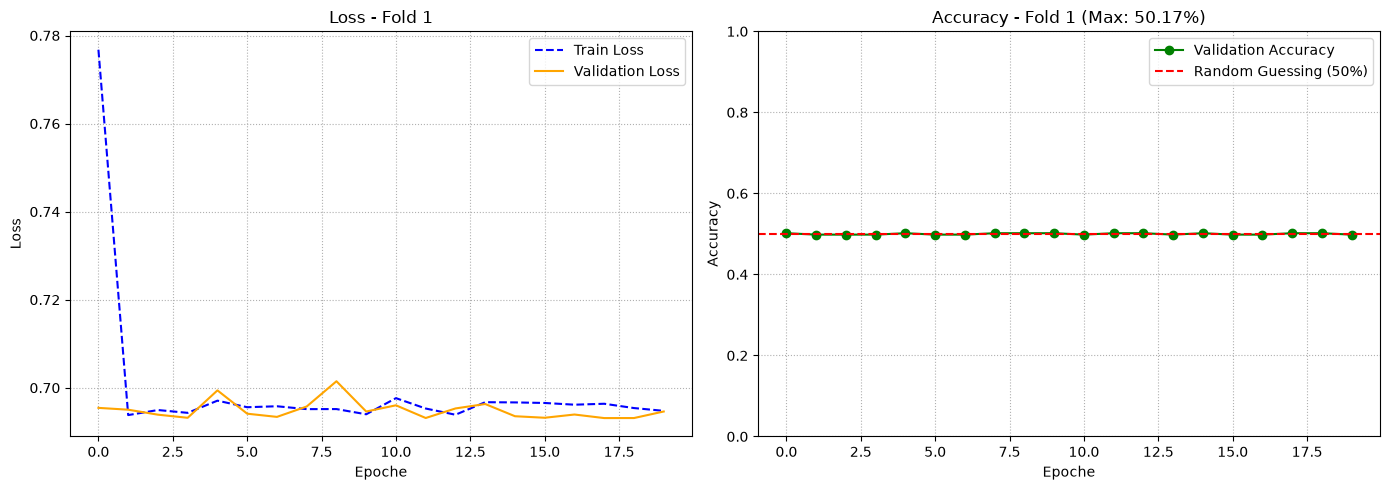


🎉 TRAINING COMPLETATO SU TUTTI I FOLD!
📊 Accuracy media cross-validation: 50.17% (± 0.00%)


In [21]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

# 1. Configurazione del Dispositivo (MPS / CUDA / CPU)
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

import torch
'''
def zscore_per_trial_torch(X, eps=1e-8):
    """
    X shape: (batch_size, n_channels, time_steps) oppure (n_trials, n_channels, time_steps)
    """
    mean = X.mean(dim=-1, keepdim=True)
    std = X.std(dim=-1, keepdim=True, unbiased=False) # unbiased=False per rispecchiare np.std
    
    # Previene divisione per zero in PyTorch
    std = torch.clamp(std, min=eps)
    
    return (X - mean) / std
'''

# 2. Parametri di Configurazione Ottimizzati
BATCH_SIZE = 64        # Ridotto a 32 per stabilizzare i gradienti sui Transformer EEG
EPOCHS = 20            # Leggermente aumentate, ci pensa l'Early Stopping a fermare tutto
LR = 1e-1              # Learning rate leggermente più prudente per il Transformer
WEIGHT_DECAY = 0     # Strong weight decay per regolarizzare contro l'overfitting
ALPHA_NOISE = 0.00      # Intensità del rumore di augmentation
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)

# Liste per raccogliere le metriche di tutti i fold
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

# ==========================================
# 3. CICLO DI TRAINING CON GROUPKFOLD
# ==========================================
for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- INIZIO TRAINING & VALIDAZIONE - FOLD {fold + 1}/5 ---")

    # A. Split dei dati grezzi
    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]

    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    '''    
# C. APPLICAZIONE DELLA TUA FUNZIONE DI NORMALIZZAZIONE PER-TRIAL
    X_train_norm = zscore_per_trial_torch(X_train_tensor)
    X_val_norm = zscore_per_trial_torch(X_val_tensor)

    print("--- Diagnostica Normalizzazione Training Set ---")
    print(f"Minimo: {X_train_norm.min().item():.4f}")
    print(f"Massimo: {X_train_norm.max().item():.4f}")
    print(f"Media globale: {X_train_norm.mean().item():.4f}")
    print(f"Deviazione standard globale: {X_train_norm.std().item():.4f}")

    # Controllo se ci sono valori anomali, NaN o Inf
    has_nan = torch.isnan(X_train_norm).any().item()
    has_inf = torch.isinf(X_train_norm).any().item()
    print(f"Presenza di NaN? {'⚠️ SÌ' if has_nan else '✅ No'}")
    print(f"Presenza di Inf? {'⚠️ SÌ' if has_inf else '✅ No'}")
    print("-" * 45)

    # E. Creazione Dataset e DataLoader PyTorch
    train_dataset = EEGDataset(X_train_norm.numpy(), y_train)
    val_dataset = EEGDataset(X_val_norm.numpy(), y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    '''

    # B. Calcolo Media e Std per-canale ESCLUSIVAMENTE sul Training Set (Prevenzione Data Leakage)
    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    # C. Normalizzazione + Data Augmentation (Rumore Gaussiano) solo sul Train
    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    # D. Normalizzazione pura sul Validation Set (usando media e std del Train)
    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

# E. Creazione Dataset e DataLoader PyTorch
    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)


    # F. Inizializzazione del Modello 
    # NOTA: Assicurati che d_model corrisponda ai canali in uscita del CNN module o gestiscilo con una Linear layer.
    model = EEGConformer(
        num_channels=64, time_steps=641, d_model=40,  # Impostato a 40 per coincidere con k=40 della CNN ed evitare mismatch
        nhead=4, num_layers=2, d_ff=160, dropout=0.5, num_classes=2
    ).to(device)
    
    # G. Ottimizzatore, Loss e Scheduler
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    #scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

    # H. Trainer personalizzato
    trainer = EEGTrainer(
        model=model, 
        criterion=criterion, 
        optimizer=optimizer,  
        device=device
    )

    # I. Training e Validazione con Early Stopping integrato
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
        train_loader=train_loader, 
        val_loader=val_loader, 
        epochs=EPOCHS,
        scheduler=None,
         max_grad_norm=3.0
    )

    fold_accuracies.append(best_val_acc)
    print(f"✅ Fold {fold + 1} completato | Miglior Val Acc: {best_val_acc*100:.2f}%")

    # Salvataggio del modello migliore assoluto
    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    # ==========================================
    # L. PLOT DELLE CURVE DI LOSS E ACCURACY
    # ==========================================
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epoche')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
print(f"\n🎉 TRAINING COMPLETATO SU TUTTI I FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")